# IMT-342 — Hito 2: integración del ABB IRB 120

**Cinemática inversa analítica, selección articular, planificación LSPB, Jacobiano, singularidades y dinámica reducida 1R.**

Fuentes: `S10_material_oficial.pdf` (guía y rúbrica del Hito 2), `S09_material_oficial.pdf` (estructura de integración) y modelo DH validado en el Hito 1. Los cálculos se importan de `src/`; el Notebook organiza los datos y presenta los resultados.

Unidades: metros, radianes y segundos. Todas las poses se expresan respecto de la base `{0}`. Las figuras y resultados se obtienen mediante la ejecución de las celdas en orden.

## 1. Modelo geométrico y datos del ensayo

El ABB IRB 120 tiene seis juntas revolutas y se modela mediante DH estándar. El TCP académico se sitúa **0.120 m sobre el eje local $z_6$** de la brida.

| Junta | $\theta$ | $d$ [m] | $a$ [m] | $\alpha$ |
|---|---|---:|---:|---|
| J1 | $q_1$ | 0.290 | 0 | $-\pi/2$ |
| J2 | $q_2-\pi/2$ | 0 | 0.270 | 0 |
| J3 | $q_3$ | 0 | 0.070 | $-\pi/2$ |
| J4 | $q_4$ | 0.302 | 0 | $+\pi/2$ |
| J5 | $q_5$ | 0 | 0 | $-\pi/2$ |
| J6 | $q_6$ | 0.072 | 0 | 0 |

**Entradas del ensayo:** en la celda siguiente se puede elegir `flange` o `tcp` y proporcionar una matriz objetivo $4\times4$. El resto del Notebook utiliza automáticamente el marco seleccionado y muestra ambos efectores para la configuración resultante.

In [14]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

RAIZ = Path.cwd().resolve()
if not (RAIZ / "src" / "pieper.py").is_file():
    RAIZ = RAIZ.parent
if not (RAIZ / "src" / "pieper.py").is_file():
    raise RuntimeError("Ejecutar desde hito2/ o hito2/notebooks/.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.irb120_fk import forward_kinematics, forward_kinematics_tcp, tcp_transform
from src.pieper import solve_pieper
from src.seleccion_pieper import filtrar_y_seleccionar_pieper
from src.lspb import planificar_lspb, VELOCIDADES_ABB_RAD_S
from src.jacobiano import jacobiano_geometrico, velocidad_cartesiana, transformaciones_intermedias
from src.singularidades import experimento_singularidad_muneca
from src.dinamica_1r import ParametrosDinamica1R, evaluar_dinamica_1r

np.set_printoptions(precision=6, suppress=True)

In [15]:
# DATOS DEL ENSAYO

MODO_POSE = "manual"           # "fk": pose de prueba; "manual": matriz indicada
MARCO_OBJETIVO = "flange"  # "flange" o "tcp"

T_MANUAL = np.array([
    [-0.205010988880,  0.463620163266,  0.861990045564,  0.291212394762],
    [-0.723346871652, -0.665055489321,  0.185662326268,  0.084251814238],
    [ 0.659348009559, -0.585454985748,  0.471701878259,  0.688380494649],
    [ 0.0,             0.0,             0.0,             1.0           ],
], dtype=float)

# Configuración para generar la pose de prueba (solo en modo "fk").
q_referencia = np.array([0.30, -0.20, 0.10, 0.20, -0.40, 0.50])  # rad

# Planificacion articular
q_inicio = np.zeros(6)                                        # rad
TF_6R = 8.0                                                   # s
ACEL_6R = np.ones(6)                                         # rad/s²

# Interpretación de la pose objetivo y conversión entre brida y TCP.
if MARCO_OBJETIVO not in ("flange", "tcp"):
    raise ValueError("MARCO_OBJETIVO debe ser 'flange' o 'tcp'.")
if MODO_POSE == "fk":
    T_objetivo = (forward_kinematics(q_referencia) if MARCO_OBJETIVO == "flange"
                  else forward_kinematics_tcp(q_referencia))
elif MODO_POSE == "manual":
    T_objetivo = np.asarray(T_MANUAL, dtype=float)
else:
    raise ValueError("MODO_POSE debe ser 'fk' o 'manual'.")

if MARCO_OBJETIVO == "flange":
    T_obj_brida = T_objetivo
    T_obj_tcp = T_obj_brida @ tcp_transform()
else:
    T_obj_tcp = T_objetivo
    T_obj_brida = T_obj_tcp @ np.linalg.inv(tcp_transform())

print(f"Pose solicitada: {MARCO_OBJETIVO} | origen: {MODO_POSE}")
print("\nPose objetivo de brida  0T6:\n", T_obj_brida)
print("\nPose objetivo de TCP    0Ttcp:\n", T_obj_tcp)

Pose solicitada: flange | origen: manual

Pose objetivo de brida  0T6:
 [[-0.205011  0.46362   0.86199   0.291212]
 [-0.723347 -0.665055  0.185662  0.084252]
 [ 0.659348 -0.585455  0.471702  0.68838 ]
 [ 0.        0.        0.        1.      ]]

Pose objetivo de TCP    0Ttcp:
 [[-0.205011  0.46362   0.86199   0.394651]
 [-0.723347 -0.665055  0.185662  0.106531]
 [ 0.659348 -0.585455  0.471702  0.744985]
 [ 0.        0.        0.        1.      ]]


## 2. Cinemática inversa analítica y selección de soluciones

La cinemática inversa de Pieper enumera las ramas de solución para la pose indicada en la sección 1. La selección posterior aplica límites nominales ABB y minimiza el desplazamiento articular ponderado respecto de $q_{inicio}$. No se realizan comprobaciones de colisión.

In [16]:
resultado_ik = solve_pieper(T_objetivo, target_frame=MARCO_OBJETIVO, q_seed=q_inicio)
resultado_sel = filtrar_y_seleccionar_pieper(resultado_ik, q_inicio)
assert resultado_ik.solutions, "No se encontraron soluciones IK para la pose indicada."
assert resultado_sel.seleccionada is not None, "No hay soluciones admisibles en los límites ABB."

print("Ramas IK:", len(resultado_ik.solutions))
print("Candidatas admisibles (incluidas vueltas de J6):", len(resultado_sel.admisibles))
print("Ramas descartadas:", len(resultado_sel.descartadas))
print("\nRama | brazo | muñeca | error posición [m] | error orientación [rad]")
for i, sol in enumerate(resultado_ik.solutions, 1):
    print(f"{i:4d} | {sol.arm_branch:>6} | {sol.wrist_branch:>6} | "
          f"{sol.position_error_m:.3e} | {sol.orientation_error_rad:.3e}")

q_final = resultado_sel.seleccionada.q.copy()
print("\nConfiguración seleccionada [rad]:", q_final)
print("Configuración seleccionada [°]:", np.rad2deg(q_final))
print("Rama:", resultado_sel.seleccionada.rama_brazo,
      resultado_sel.seleccionada.rama_muneca)
print("Costo:", resultado_sel.seleccionada.costo)
if resultado_sel.descartadas:
    print("\nDescartes por límites:")
    for s in resultado_sel.descartadas:
        print(s.rama_brazo, s.rama_muneca, s.violaciones)

Ramas IK: 8
Candidatas admisibles (incluidas vueltas de J6): 5
Ramas descartadas: 6

Rama | brazo | muñeca | error posición [m] | error orientación [rad]
   1 | base_directa/codo_+ | muneca_+ | 9.424e-15 | 1.024e-13
   2 | base_directa/codo_+ | muneca_- | 9.427e-15 | 1.022e-13
   3 | base_directa/codo_- | muneca_+ | 9.172e-15 | 1.138e-13
   4 | base_directa/codo_- | muneca_- | 9.167e-15 | 1.135e-13
   5 | base_opuesta/codo_+ | muneca_+ | 9.324e-15 | 7.656e-14
   6 | base_opuesta/codo_+ | muneca_- | 9.374e-15 | 7.648e-14
   7 | base_opuesta/codo_- | muneca_+ | 9.329e-15 | 7.580e-13
   8 | base_opuesta/codo_- | muneca_- | 9.329e-15 | 7.572e-13

Configuración seleccionada [rad]: [ 0.3 -0.2  0.1  0.2 -0.4  0.5]
Configuración seleccionada [°]: [ 17.188734 -11.459156   5.729578  11.459156 -22.918312  28.64789 ]
Rama: base_directa/codo_+ muneca_-
Costo: 0.589999999999427

Descartes por límites:
base_directa/codo_+ muneca_+ [{'junta': 'J4', 'angulo_grados': -168.54084409758147, 'minimo_grados'

## 3. Verificación mediante cinemática directa: brida y TCP

Se reconstruyen ambas poses del efector a partir de las soluciones IK. La verificación principal compara la pose del marco solicitado; la relación geométrica brida–TCP se comprueba por separado.

In [17]:
def errores_fk(T_observada, T_deseada):
    ep = float(np.linalg.norm(T_observada[:3, 3] - T_deseada[:3, 3]))
    E = T_deseada[:3, :3].T @ T_observada[:3, :3]
    v = np.array([E[2, 1]-E[1, 2], E[0, 2]-E[2, 0], E[1, 0]-E[0, 1]])
    er = float(np.arctan2(0.5 * np.linalg.norm(v),
                          0.5 * (np.trace(E) - 1.0)))
    return ep, er

fk_elegida_brida = forward_kinematics(q_final)
fk_elegida_tcp = forward_kinematics_tcp(q_final)

print("MARCO  | error posición [m] | error orientación [rad]")
for nombre, calculada, deseada in (
    ("Brida", fk_elegida_brida, T_obj_brida),
    ("TCP  ", fk_elegida_tcp, T_obj_tcp),
):
    ep, er = errores_fk(calculada, deseada)
    print(f"{nombre:6} | {ep:18.3e} | {er:23.3e}")
    assert ep < 1e-7 and er < 1e-6

for sol in resultado_ik.solutions:
    T_c = (forward_kinematics(sol.q) if MARCO_OBJETIVO == "flange"
           else forward_kinematics_tcp(sol.q))
    ep, er = errores_fk(T_c, T_objetivo)
    assert ep < 1e-7 and er < 1e-6

np.testing.assert_allclose(fk_elegida_tcp, fk_elegida_brida @ tcp_transform(), atol=1e-10)
print("FK de todas las ramas y relación brida–TCP: OK")

MARCO  | error posición [m] | error orientación [rad]
Brida  |          9.427e-15 |               1.022e-13
TCP    |          2.496e-14 |               1.022e-13
FK de todas las ramas y relación brida–TCP: OK


### 3.1. Representación espacial de brida y TCP

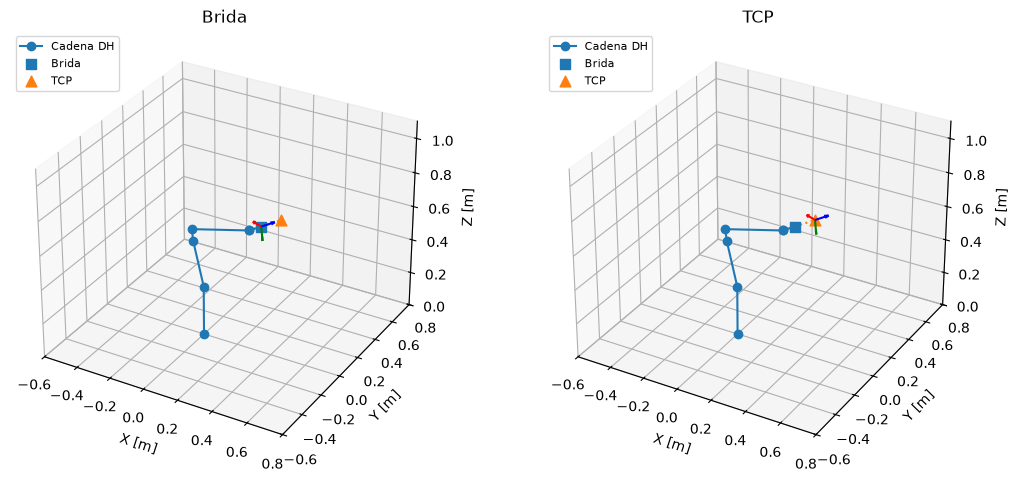

In [18]:
# Representación de la misma configuración, con brida y TCP identificados.
transf = transformaciones_intermedias(q_final)
puntos = np.array([T[:3, 3] for T in transf])
fig = plt.figure(figsize=(11, 4.8))
for panel, (titulo, T_fin) in enumerate((
    ("Brida", fk_elegida_brida), ("TCP", fk_elegida_tcp)), 1
):
    ax = fig.add_subplot(1, 2, panel, projection="3d")
    ax.plot(puntos[:, 0], puntos[:, 1], puntos[:, 2], "o-", label="Cadena DH")
    ax.scatter(*fk_elegida_brida[:3, 3], marker="s", s=55, label="Brida")
    ax.scatter(*fk_elegida_tcp[:3, 3], marker="^", s=60, label="TCP")
    ax.plot([fk_elegida_brida[0, 3], fk_elegida_tcp[0, 3]],
            [fk_elegida_brida[1, 3], fk_elegida_tcp[1, 3]],
            [fk_elegida_brida[2, 3], fk_elegida_tcp[2, 3]], ":")
    p = T_fin[:3, 3]
    R = T_fin[:3, :3]
    for k, color in enumerate(("r", "g", "b")):
        ax.quiver(*p, *(0.08 * R[:, k]), color=color)
    ax.set(xlabel="X [m]", ylabel="Y [m]", zlabel="Z [m]", title=titulo)
    ax.set_xlim(-0.6, 0.8)
    ax.set_ylim(-0.6, 0.8)
    ax.set_zlim(0.0, 1.1)
    ax.set_box_aspect((1.4, 1.4, 1.1))
    ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

## 4. Jacobiano geométrico: brida y TCP

Para cada junta revoluta se utiliza $J_{v,i}=z_{i-1}\times(p_e-o_{i-1})$ y $J_{\omega,i}=z_{i-1}$. La estructura es idéntica para ambos efectores; la parte lineal se calcula en el punto elegido.

In [19]:
J_brida = jacobiano_geometrico(q_final, target_frame="flange")
J_tcp = jacobiano_geometrico(q_final, target_frame="tcp")
z0 = np.array([0.0, 0.0, 1.0])
for nombre, J_actual, T_actual in (
    ("Brida", J_brida, fk_elegida_brida),
    ("TCP", J_tcp, fk_elegida_tcp),
):
    columna_j1_manual = np.r_[np.cross(z0, T_actual[:3, 3]), z0]
    np.testing.assert_allclose(J_actual[:, 0], columna_j1_manual, atol=1e-11)
    print(f"{nombre}: Jacobiano 6×6; columna J1 verificada.")
print("\nJ de brida:\n", J_brida)
print("\nJ de TCP:\n", J_tcp)

Brida: Jacobiano 6×6; columna J1 verificada.
TCP: Jacobiano 6×6; columna J1 verificada.

J de brida:
 [[-0.084252  0.380587  0.127788  0.008652  0.028957 -0.      ]
 [ 0.291212  0.117729  0.03953  -0.026088  0.022749  0.      ]
 [ 0.       -0.303104 -0.356745 -0.005542 -0.061871  0.      ]
 [ 0.       -0.29552  -0.29552   0.950564 -0.308577  0.86199 ]
 [ 0.        0.955336  0.955336  0.294044  0.930432  0.185662]
 [ 1.        0.        0.        0.099833  0.197677  0.471702]]

J de TCP:
 [[-0.106531  0.434664  0.181864  0.023072  0.07722  -0.      ]
 [ 0.394651  0.134457  0.056257 -0.069567  0.060663  0.      ]
 [ 0.       -0.408507 -0.462148 -0.01478  -0.164988  0.      ]
 [ 0.       -0.29552  -0.29552   0.950564 -0.308577  0.86199 ]
 [ 0.        0.955336  0.955336  0.294044  0.930432  0.185662]
 [ 1.        0.        0.        0.099833  0.197677  0.471702]]


## 5. Singularidad de muñeca

Se aproxima $q_5\to0$ con las demás articulaciones fijas. Se documentan la pérdida de rango del Jacobiano y el incremento de velocidades articulares asociado a una consigna cartesiana constante. Es un experimento independiente de la trayectoria LSPB.

In [20]:
exp_sing = experimento_singularidad_muneca()
print(" q5 [rad]  rango    sigma_min(normalizada)       norma qdot [rad/s]")
for q5, rango, sigma, norma in zip(exp_sing.angulos_q5_rad,
                                   exp_sing.rangos,
                                   exp_sing.sigma_min,
                                   exp_sing.normas_qdot):
    print(f"{q5:8.5f}    {rango:d}       {sigma:12.5e}           {norma:12.5g}")
assert exp_sing.rangos[-1] == 5
assert np.all(exp_sing.rangos[:-1] == 6)
assert np.isnan(exp_sing.normas_qdot[-1])
print("Dirección cartesiana normalizada perdida:",
      exp_sing.direccion_perdida_normalizada)
print("Modo nulo articular:", exp_sing.modo_nulo_articular)

 q5 [rad]  rango    sigma_min(normalizada)       norma qdot [rad/s]
 0.20000    6        2.83027e-02                 0.3531
 0.10000    6        1.42894e-02                0.69971
 0.05000    6        7.17080e-03                 1.3945
 0.01000    6        1.43749e-03                 6.9566
 0.00100    6        1.43813e-04                 69.535
 0.00010    6        1.43819e-05                 695.32
 0.00000    5        5.19122e-17                    nan
Dirección cartesiana normalizada perdida: [ 0.35788  -0.860402 -0.240063  0.004437 -0.100197  0.252864]
Modo nulo articular: [ 0.        0.       -0.       -0.707107  0.        0.707107]


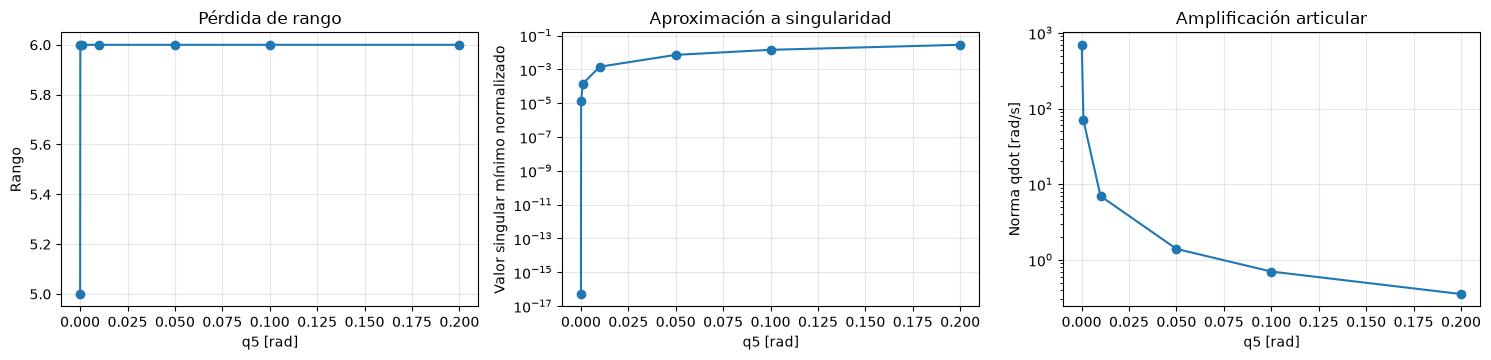

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.7))
axes[0].plot(exp_sing.angulos_q5_rad, exp_sing.rangos, "o-")
axes[0].set(ylabel="Rango", xlabel="q5 [rad]", title="Pérdida de rango")
axes[1].semilogy(exp_sing.angulos_q5_rad, exp_sing.sigma_min, "o-")
axes[1].set(ylabel="Valor singular mínimo normalizado", xlabel="q5 [rad]",
            title="Aproximación a singularidad")
mask = np.isfinite(exp_sing.normas_qdot)
axes[2].semilogy(exp_sing.angulos_q5_rad[mask], exp_sing.normas_qdot[mask], "o-")
axes[2].set(ylabel="Norma qdot [rad/s]", xlabel="q5 [rad]",
            title="Amplificación articular")
for ax in axes: ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 6. Planificación articular LSPB

Con $q_{inicio}$ y la solución admisible $q_{final}$ se calcula un perfil LSPB de reposo a reposo. El tiempo total y las aceleraciones del ensayo se encuentran en la sección 1; no representan límites certificados de aceleración ABB.

In [22]:
perfil_6r = planificar_lspb(q_inicio, q_final, TF_6R, ACEL_6R)
t_6r = np.linspace(0.0, perfil_6r.tf, 401)
tray = perfil_6r.evaluar(t_6r)
np.testing.assert_allclose(tray.q[0], q_inicio, atol=1e-10)
np.testing.assert_allclose(tray.q[-1], q_final, atol=1e-10)
np.testing.assert_allclose(tray.qdot[[0, -1]], 0, atol=1e-10)
assert np.all(np.abs(tray.qdot) <= VELOCIDADES_ABB_RAD_S + 1e-10)
print("Tiempo total [s]:", perfil_6r.tf)
print("Tiempo de mezcla por junta [s]:", perfil_6r.tc)
print("Velocidad de crucero [rad/s]:", perfil_6r.v_crucero)

Tiempo total [s]: 8.0
Tiempo de mezcla por junta [s]: [0.037677 0.025079 0.01252  0.025079 0.050316 0.062996]
Velocidad de crucero [rad/s]: [ 0.037677 -0.025079  0.01252   0.025079 -0.050316  0.062996]


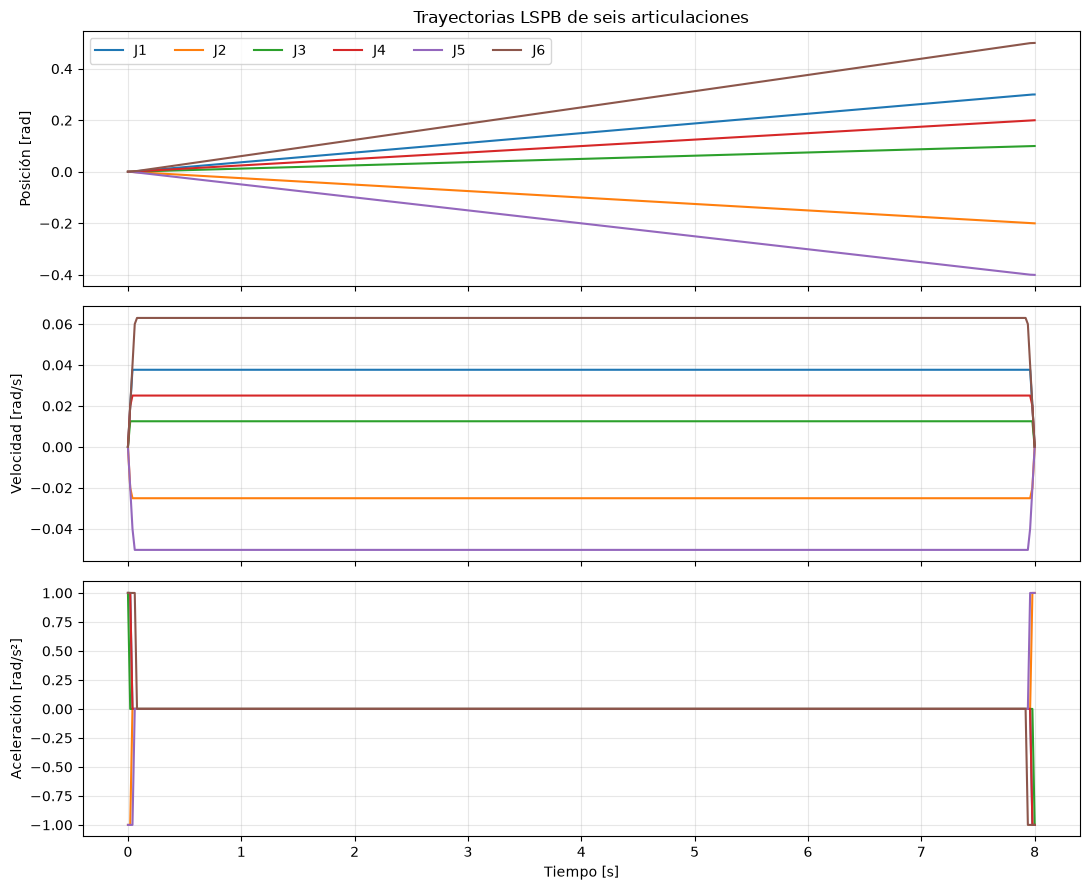

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for j in range(6):
    etiqueta = f"J{j+1}"
    axes[0].plot(t_6r, tray.q[:, j], label=etiqueta)
    axes[1].plot(t_6r, tray.qdot[:, j], label=etiqueta)
    axes[2].plot(t_6r, tray.qddot[:, j], label=etiqueta)
for ax, ylabel in zip(axes,
    ["Posición [rad]", "Velocidad [rad/s]", "Aceleración [rad/s²]"]):
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
axes[0].legend(ncol=6, loc="best")
axes[0].set_title("Trayectorias LSPB de seis articulaciones")
axes[-1].set_xlabel("Tiempo [s]")
fig.tight_layout()
plt.show()

## 7. Dinámica pedagógica reducida 1R

**Alcance y fuente:** según el ejercicio oficial W10-S01, S10 pp. 16–17, se utiliza
\[
\tau(t)=J_{1R}\ddot q(t)+mg\ell_c\sin q(t)
=\tau_{inercial}(t)+\tau_{gravitatorio}(t).
\]

En este modelo particular \(J_{1R}\) es constante y no se introduce un término independiente de Coriolis. Esto **no describe la dinámica acoplada de seis articulaciones** del ABB IRB 120. El ejemplo es una trayectoria **1R propia del docente**, independiente del movimiento 6R de las secciones previas.

Parámetros didácticos: \(q_i=0\), \(q_f=2\,\mathrm{rad}\), \(t_f=3\,\mathrm s\), \(a=1\,\mathrm{rad/s^2}\), \(J_{1R}=0.25\,\mathrm{kg\,m^2}\), \(m=1\,\mathrm{kg}\), \(\ell_c=0.5\,\mathrm m\), \(g=9.81\,\mathrm{m/s^2}\).

In [24]:
perfil_1r = planificar_lspb([0], [2], 3.0, [1.0])
param_1r = ParametrosDinamica1R(inercia_kg_m2=0.25,
                                masa_kg=1.0,
                                longitud_cm_m=0.5,
                                gravedad_m_s2=9.81)
t_1r = np.linspace(0.0, 3.0, 601)
din = evaluar_dinamica_1r(perfil_1r, t_1r, param_1r)
control = evaluar_dinamica_1r(perfil_1r, 2.5, param_1r)
print(f"Verificación docente en t=2.5 s: q={control.q_rad:.6f} rad, "
      f"qddot={control.qddot_rad_s2:.6f} rad/s², "
      f"tau={control.tau_total_nm:.6f} N·m")
np.testing.assert_allclose(control.q_rad, 1.875, atol=1e-12)
np.testing.assert_allclose(control.qddot_rad_s2, -1.0, atol=1e-12)
np.testing.assert_allclose(control.tau_total_nm,
                           -0.25 + 4.905*np.sin(1.875), atol=1e-10)

crucero = evaluar_dinamica_1r(perfil_1r, 1.5, param_1r)
assert abs(crucero.tau_inercial_nm) < 1e-12
print(f"Crucero en t=1.5 s: tau_inercial={crucero.tau_inercial_nm:.6f}, "
      f"tau_gravitatorio={crucero.tau_gravitatorio_nm:.6f} N·m")

Verificación docente en t=2.5 s: q=1.875000 rad, qddot=-1.000000 rad/s², tau=4.429791 N·m
Crucero en t=1.5 s: tau_inercial=0.000000, tau_gravitatorio=4.127415 N·m


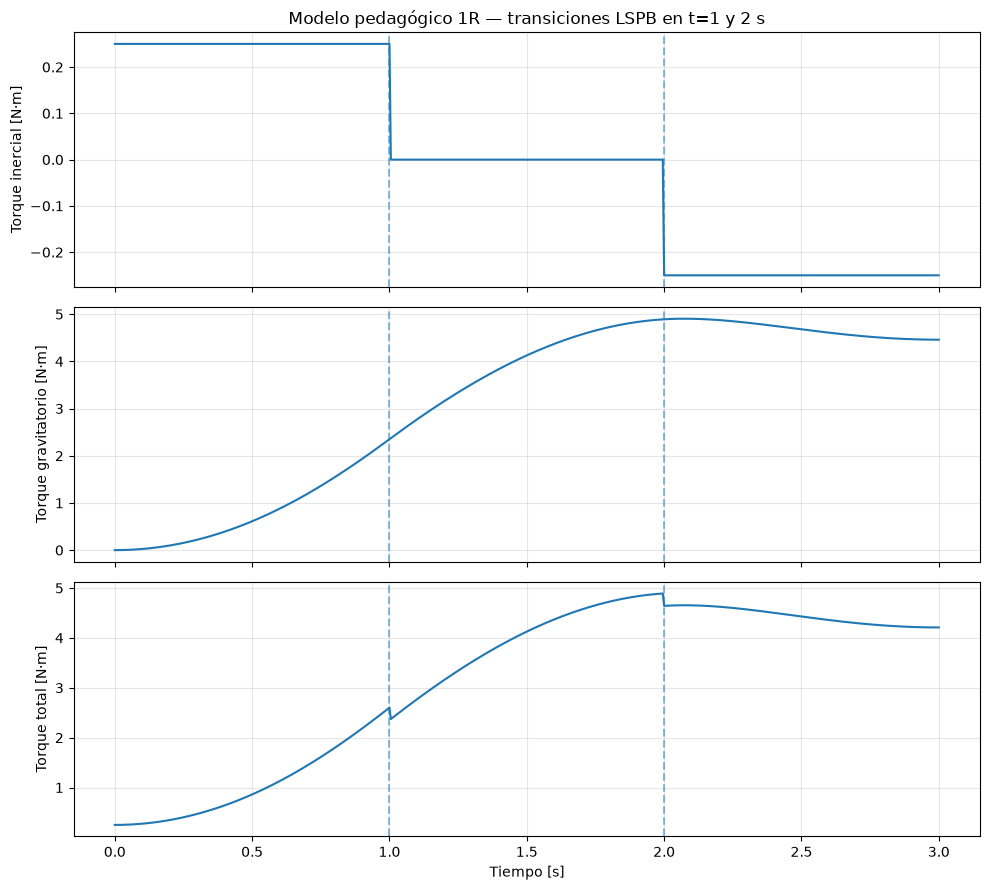

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
axes[0].plot(t_1r, din.tau_inercial_nm, label="Inercial")
axes[1].plot(t_1r, din.tau_gravitatorio_nm, label="Gravitatorio")
axes[2].plot(t_1r, din.tau_total_nm, label="Total")
for ax, etiqueta in zip(axes,
                       ["Torque inercial [N·m]", "Torque gravitatorio [N·m]",
                        "Torque total [N·m]"]):
    ax.set_ylabel(etiqueta)
    ax.axvline(1.0, linestyle="--", alpha=0.5)
    ax.axvline(2.0, linestyle="--", alpha=0.5)
    ax.grid(True, alpha=0.3)
axes[0].set_title("Modelo pedagógico 1R — transiciones LSPB en t=1 y 2 s")
axes[2].set_xlabel("Tiempo [s]")
fig.tight_layout()
plt.show()

## 8. Velocidades cartesianas durante LSPB: brida y TCP

La misma trayectoria articular $q(t)$ se evalúa para ambos efectores mediante $V=J(q)\dot q$. Sus velocidades angulares coinciden, mientras que las componentes lineales difieren debido al desplazamiento fijo de la brida al TCP.

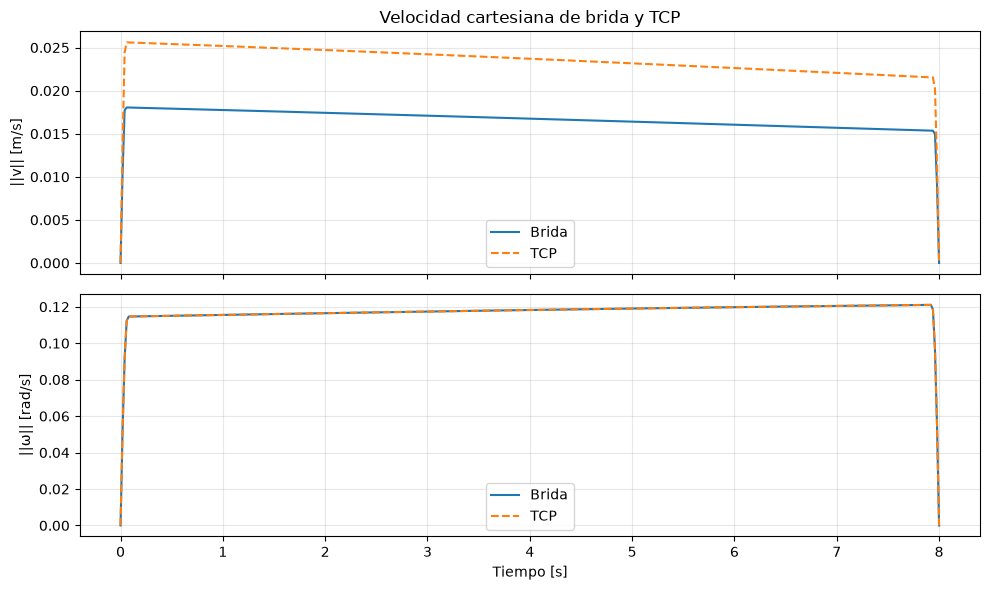

In [26]:
twist_brida = np.array([velocidad_cartesiana(q, qd, target_frame="flange")
                       for q, qd in zip(tray.q, tray.qdot)])
twist_tcp = np.array([velocidad_cartesiana(q, qd, target_frame="tcp")
                     for q, qd in zip(tray.q, tray.qdot)])
np.testing.assert_allclose(twist_brida[[0, -1]], 0, atol=1e-9)
np.testing.assert_allclose(twist_tcp[[0, -1]], 0, atol=1e-9)
np.testing.assert_allclose(twist_brida[:, 3:], twist_tcp[:, 3:], atol=1e-10)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(t_6r, np.linalg.norm(twist_brida[:, :3], axis=1), label="Brida")
axes[0].plot(t_6r, np.linalg.norm(twist_tcp[:, :3], axis=1), "--", label="TCP")
axes[1].plot(t_6r, np.linalg.norm(twist_brida[:, 3:], axis=1), label="Brida")
axes[1].plot(t_6r, np.linalg.norm(twist_tcp[:, 3:], axis=1), "--", label="TCP")
axes[0].set(ylabel="||v|| [m/s]", title="Velocidad cartesiana de brida y TCP")
axes[1].set(xlabel="Tiempo [s]", ylabel="||ω|| [rad/s]")
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 9. Resultados y alcance

- Pieper: ramas verificadas mediante cinemática directa y filtradas por límites nominales ABB.
- Brida y TCP: poses reconstruidas, visualización espacial, Jacobianos y velocidades cartesianas.
- Singularidad: disminución del rango al aproximar J5 a cero y amplificación de velocidad articular.
- LSPB: posición, velocidad y aceleración articular, con reposo en ambos extremos.
- Dinámica 1R: torque inercial, gravitatorio y total para el ejemplo académico oficial.

Los ensayos no consideran colisiones, control del robot físico ni torques dinámicos del manipulador completo. La validez de una nueva pose manual depende de que sea alcanzable y admita una solución dentro de los límites articulares.